#  Modelos alternativos
Este avance implica construir múltiples modelos (individuales, no ensambles) relevantes para resolver el problema y evaluar su desempeño. Diferentes algoritmos pueden comportarse de manera óptima en diferentes tipos de datos o tareas. La construcción de modelos alternativos permite explorar y evaluar cuál de ellos proporciona el mejor rendimiento para un problema particular.

Además, los modelos se pueden ajustar para determinar si se puede mejorar su rendimiento. Diferentes configuraciones de hiperparámetros pueden afectar significativamente el rendimiento de un modelo. Construir modelos alternativos implica explorar y ajustar estos hiperparámetros para encontrar la configuración óptima.

Las siguientes son acciones que deberás abordar en este avance:

* Construir al menos 6 modelos diferentes (individuales, no ensambles), utilizando algoritmos variados.
* Comparar el rendimiento de los modelos obtenidos.
* Seleccionar los dos modelos que proporcionen el mejor rendimiento.
* Ajustar los dos mejores modelos.
* Elegir el modelo individual final.

# Modelos
Preparamiento de datos para procesado posterior (ChatGPT-6 Luna):

In [228]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

RANDOM_STATE = 42
TEST_SIZE = 0.25

# Ingresa los archivos que usó la preparación de datos de tu libreta.
annotations_path=Path("../DataCapture/anotaciones_baseline.csv")
heads_path=Path("../DataCapture/mediciones_mascara_rostro.csv")

IMAGE_COL = "imagen"
X_COL, Y_COL, W_COL, H_COL, ImageWidth, ImageHeight = "x", "y", "w", "h", "image_width", "image_height"

annotations = pd.read_csv(annotations_path)
heads = pd.read_csv(heads_path)

# Verificar que existan las columnas esperadas.
required_annotations = {IMAGE_COL, X_COL, Y_COL, W_COL, H_COL}
required_heads = {IMAGE_COL, X_COL, Y_COL, W_COL, H_COL}

missing_annotations = required_annotations - set(annotations.columns)
missing_heads = required_heads - set(heads.columns)

if missing_annotations:
    raise ValueError(
        f"Faltan columnas en anotaciones: {sorted(missing_annotations)}"
    )
if missing_heads:
    raise ValueError(
        f"Faltan columnas en mediciones de cabeza: {sorted(missing_heads)}"
    )

# Normalizar el identificador de imagen para que coincida entre archivos.
annotations[IMAGE_COL] = annotations[IMAGE_COL].astype(str).map(
    lambda value: Path(value).name
)
heads[IMAGE_COL] = heads[IMAGE_COL].astype(str).map(
    lambda value: Path(value).name
)

# Convertir coordenadas a valores numéricos y descartar filas incompletas.
for col in [X_COL, Y_COL, W_COL, H_COL]:
    annotations[col] = pd.to_numeric(annotations[col], errors="coerce")
    heads[col] = pd.to_numeric(heads[col], errors="coerce")

annotations = annotations.dropna(
    subset=[IMAGE_COL, X_COL, Y_COL, W_COL, H_COL]
).copy()
heads = heads.dropna(
    subset=[IMAGE_COL, X_COL, Y_COL, W_COL, H_COL]
).copy()

# Ignorar cajas con ancho o alto no válidos.
annotations = annotations[
    (annotations[W_COL] > 0) & (annotations[H_COL] > 0)
].copy()
heads = heads[
    (heads[W_COL] > 0) & (heads[H_COL] > 0)
].copy()

# Usa las dimensiones de cada imagen si están en el CSV de anotaciones.
if {"image_width", "image_height"}.issubset(annotations.columns):
    annotations["img_w"] = pd.to_numeric(
        annotations["image_width"], errors="coerce"
    )
    annotations["img_h"] = pd.to_numeric(
        annotations["image_height"], errors="coerce"
    )
    annotations = annotations.dropna(subset=["img_w", "img_h"])
else:
    # La libreta recuperada asumía imágenes de 640 × 480.
    # Cambia estos valores si tus imágenes tienen otras dimensiones.
    IMG_W = int(input("Ancho de imagen en píxeles (por ejemplo, 640): "))
    IMG_H = int(input("Alto de imagen en píxeles (por ejemplo, 480): "))
    annotations["img_w"] = IMG_W
    annotations["img_h"] = IMG_H

if (annotations["img_w"] <= 0).any() or (annotations["img_h"] <= 0).any():
    raise ValueError("Se encontraron dimensiones de imagen inválidas.")

# Renombrar las columnas de la cabeza para no confundirlas con las del objeto.
heads = heads[[IMAGE_COL, X_COL, Y_COL, W_COL, H_COL]].rename(
    columns={
        X_COL: "head_x",
        Y_COL: "head_y",
        W_COL: "head_w",
        H_COL: "head_h",
    }
)

heads["head_cx"] = heads["head_x"] + heads["head_w"] / 2
heads["head_cy"] = heads["head_y"] + heads["head_h"] / 2

# Centro de cada objeto anotado.
annotations = annotations.reset_index(drop=True)
annotations["_object_id"] = np.arange(len(annotations))
annotations["obj_cx"] = annotations[X_COL] + annotations[W_COL] / 2
annotations["obj_cy"] = annotations[Y_COL] + annotations[H_COL] / 2

# Asociar cada objeto con la cabeza más cercana de la misma imagen.
pairs = annotations[
    ["_object_id", IMAGE_COL, "obj_cx", "obj_cy"]
].merge(heads, on=IMAGE_COL, how="inner")

if pairs.empty:
    raise ValueError(
        "No se encontraron imágenes coincidentes entre anotaciones y cabezas."
    )

pairs["distancia"] = np.hypot(
    pairs["obj_cx"] - pairs["head_cx"],
    pairs["obj_cy"] - pairs["head_cy"]
)

closest_rows = pairs.groupby("_object_id")["distancia"].idxmin()
nearest_heads = pairs.loc[
    closest_rows,
    ["_object_id", "head_x", "head_y", "head_w", "head_h", "head_cx", "head_cy"]
]

df = annotations.merge(nearest_heads, on="_object_id", how="inner")

# Característica de hora extraída del nombre de imagen, como en la libreta.
hour_text = df[IMAGE_COL].str.extract(r"_(\d{2})\d{4}_", expand=False)
if hour_text.isna().any():
    examples = df.loc[hour_text.isna(), IMAGE_COL].head().tolist()
    raise ValueError(
        "No pude extraer la hora de algunos nombres de imagen. "
        f"Revisa el patrón o modifica la expresión regular. Ejemplos: {examples}"
    )
df["hora"] = hour_text.astype(int)

# Objetivo continuo: logaritmo del área relativa del objeto.
df["area_rel"] = (
    (df[W_COL] * df[H_COL]) / (df["img_w"] * df["img_h"])
)
df["log_area_rel"] = np.log1p(df["area_rel"] * 1000)

# Entradas: solo mediciones de cabeza y hora.
# No se incluyen x, y, w, h del objeto porque se usan para calcular el objetivo.
df["head_area_rel"] = (
    (df["head_w"] * df["head_h"]) / (df["img_w"] * df["img_h"])
)
df["log_head_area_rel"] = np.log1p(df["head_area_rel"] * 1000)
df["head_cx_rel"] = df["head_cx"] / df["img_w"]
df["head_cy_rel"] = df["head_cy"] / df["img_h"]

FEATURES = [
    "log_head_area_rel",
    "head_w",
    "head_h",
    "head_cx_rel",
    "head_cy_rel",
    "hora",
]
TARGET = "log_area_rel"
GROUP_COL = IMAGE_COL

# Conservar solo filas completas para las variables que se modelarán.
df_model = df.dropna(subset=FEATURES + [TARGET, GROUP_COL]).copy()

X = df_model[FEATURES]
y = df_model[TARGET]
groups = df_model[GROUP_COL]

if groups.nunique() < 3:
    raise ValueError(
        "Hay muy pocas imágenes distintas para separar train/test y validar."
    )

# Separación agrupada: todas las observaciones de una imagen quedan juntas.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# Comprobación explícita para detectar fuga entre imágenes.
assert set(groups_train).isdisjoint(set(groups_test))

# Validación cruzada agrupada, solo sobre entrenamiento.
n_splits = min(5, groups_train.nunique())
if n_splits < 2:
    raise ValueError("No hay suficientes imágenes en train para validación cruzada.")

cv = GroupKFold(n_splits=n_splits)

print(f"Filas totales: {len(df_model)}")
print(f"Imágenes totales: {groups.nunique()}")
print(f"Train: {len(X_train)} filas | {groups_train.nunique()} imágenes")
print(f"Test:  {len(X_test)} filas | {groups_test.nunique()} imágenes")
print(f"Validación cruzada: {n_splits} particiones agrupadas por imagen")
print(f"Características: {FEATURES}")
print(f"Objetivo: {TARGET}")

display(df_model[FEATURES + [TARGET]].head())

Filas totales: 66
Imágenes totales: 38
Train: 48 filas | 28 imágenes
Test:  18 filas | 10 imágenes
Validación cruzada: 5 particiones agrupadas por imagen
Características: ['log_head_area_rel', 'head_w', 'head_h', 'head_cx_rel', 'head_cy_rel', 'hora']
Objetivo: log_area_rel


,log_head_area_rel,head_w,head_h,head_cx_rel,head_cy_rel,hora,log_area_rel
0,4.983517,170,262,0.295312,0.504167,15,2.161286
1,4.854103,181,216,0.527344,0.531250,15,2.212800
2,4.528411,177,159,0.466406,0.165625,15,0.590027
3,5.491823,330,225,0.464062,0.765625,15,0.630690
4,5.773174,325,303,0.392969,0.684375,15,0.410660


## Construcción de modelos múltiples

In [229]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, GammaRegressor, BayesianRidge, SGDRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate, learning_curve, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import f_regression

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

def construir_modelos():
    return {"Ingenuo (media)": DummyRegressor(strategy="mean"),
            "Regresión lineal": make_pipeline(StandardScaler(), LinearRegression()),
            "Ridge (alpha=10)": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
            "Gamma Regression": make_pipeline(StandardScaler(),GammaRegressor()),
            "Bayesian Ridge": make_pipeline(StandardScaler(),BayesianRidge()),
            "SGDRegressor": make_pipeline(StandardScaler(),SGDRegressor()),
            "Random Forest": RandomForestRegressor(n_estimators=300,max_depth=3,min_samples_leaf=3,random_state=42,n_jobs=-1),
            "Red neuronal (MLP)": make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(8,),solver="lbfgs",alpha=1.0,max_iter=2000,random_state=42))
            }

modelos = {n: m.fit(X_train, y_train) for n, m in construir_modelos().items()}

Entrenamiento: (48, 6) | Prueba: (18, 6)


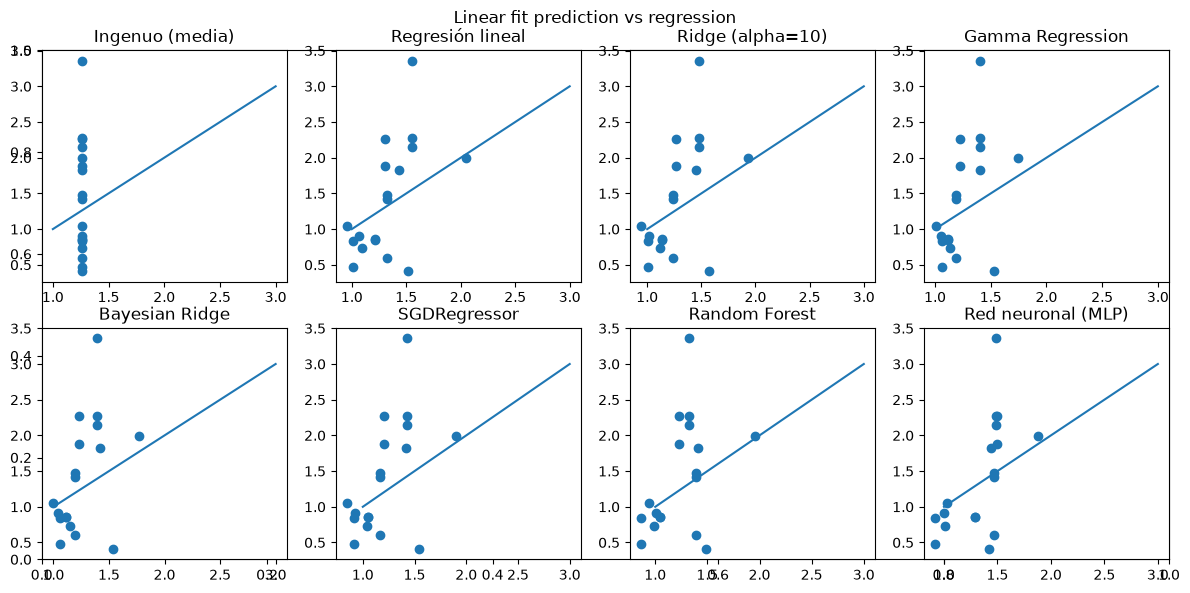

In [230]:
i=0
plt.subplots(figsize=[12,6])
plt.suptitle("Linear fit prediction vs regression")
plt.tight_layout()
for model in modelos:
    i+=1
    y_hat=modelos[model].predict(X_test)
    plt.subplot(2,4,i)
    plt.scatter(y_hat,y_test)
    plt.plot([1,3],[1,3])
    plt.title(model)

### Funcion reutilizable para estadísticos

In [231]:
def estadisticos(model,X_train,y_train,coef_feat,name):
    # 1. Filtro: estadístico F y valor p
    F, p = f_regression(X_train, y_train)
    filtro = pd.DataFrame({"F": F, "p_valor": p}, index=FEATURES).sort_values("F", ascending=False)

    # 2. Coeficientes estandarizados
    coefs = pd.Series(coef_feat, index=FEATURES).sort_values()

    # 3. Importancia por permutación (sobre entrenamiento)
    perm = permutation_importance(model, X_train, y_train, n_repeats=50, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
    perm_s = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
    perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_s.index]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].barh(filtro.index[::-1], filtro["F"][::-1], color="steelblue")
    axes[0].set_title("Prueba F univariada")
    axes[1].barh(coefs.index, coefs.values, color=np.where(coefs.values >= 0, "seagreen", "indianred"))
    axes[1].set_title(f"Coeficientes estandarizados {name}")
    axes[2].barh(perm_s.index, perm_s.values, xerr=perm_std.values, color="darkorange")
    axes[2].set_title("Importancia por permutación (aumento del MAE)")
    plt.tight_layout()
    plt.show()

    filtro.round(4)

### Función reutilizable para curvas de aprendizaje

In [232]:
def aprendizaje_curva(model_pipeline,X_train,y_train,name="modelo"):
    sizes, tr_sc, va_sc = learning_curve(
        model_pipeline, X_train, y_train, groups=g_train, cv=cv,
        train_sizes=np.linspace(0.3, 1.0, 6), scoring="neg_mean_absolute_error")

    plt.figure(figsize=(8, 5))
    plt.plot(sizes, -tr_sc.mean(axis=1), "o-", label="Entrenamiento")
    plt.plot(sizes, -va_sc.mean(axis=1), "o-", label="Validación")
    plt.fill_between(sizes, -va_sc.mean(axis=1) - va_sc.std(axis=1), -va_sc.mean(axis=1) + va_sc.std(axis=1), alpha=0.2)
    plt.axhline(cv_res.loc["Ingenuo (media)", "MAE val"], color="gray", linestyle="--", label="Ingenuo (validación)")
    plt.xlabel("Tamaño del conjunto de entrenamiento")
    plt.ylabel("MAE (escala logarítmica)")
    plt.title(f"Curva de aprendizaje {name}")
    plt.legend()
    plt.show()


## Modelo 1 - Regresión lineal

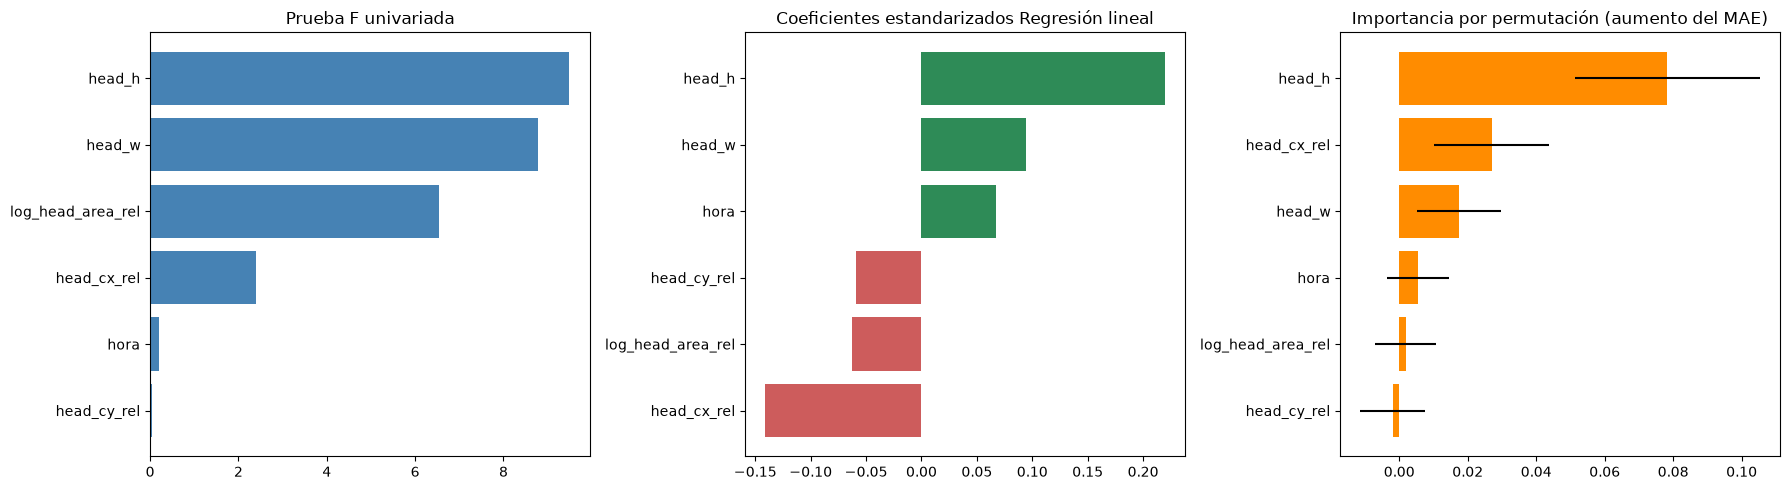

In [233]:
estadisticos(modelos["Regresión lineal"],X_train,y_train,modelos["Regresión lineal"].named_steps["linearregression"].coef_,"Regresión lineal")

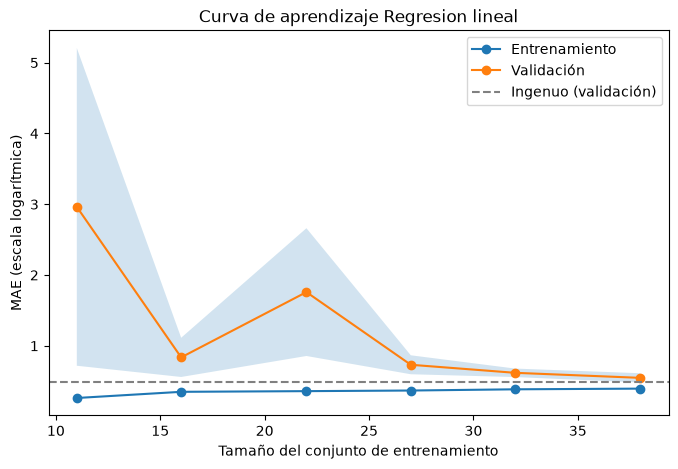

In [234]:
aprendizaje_curva(modelos["Regresión lineal"],X_train,y_train,"Regresion lineal")

## Modelo 2 - Ridge

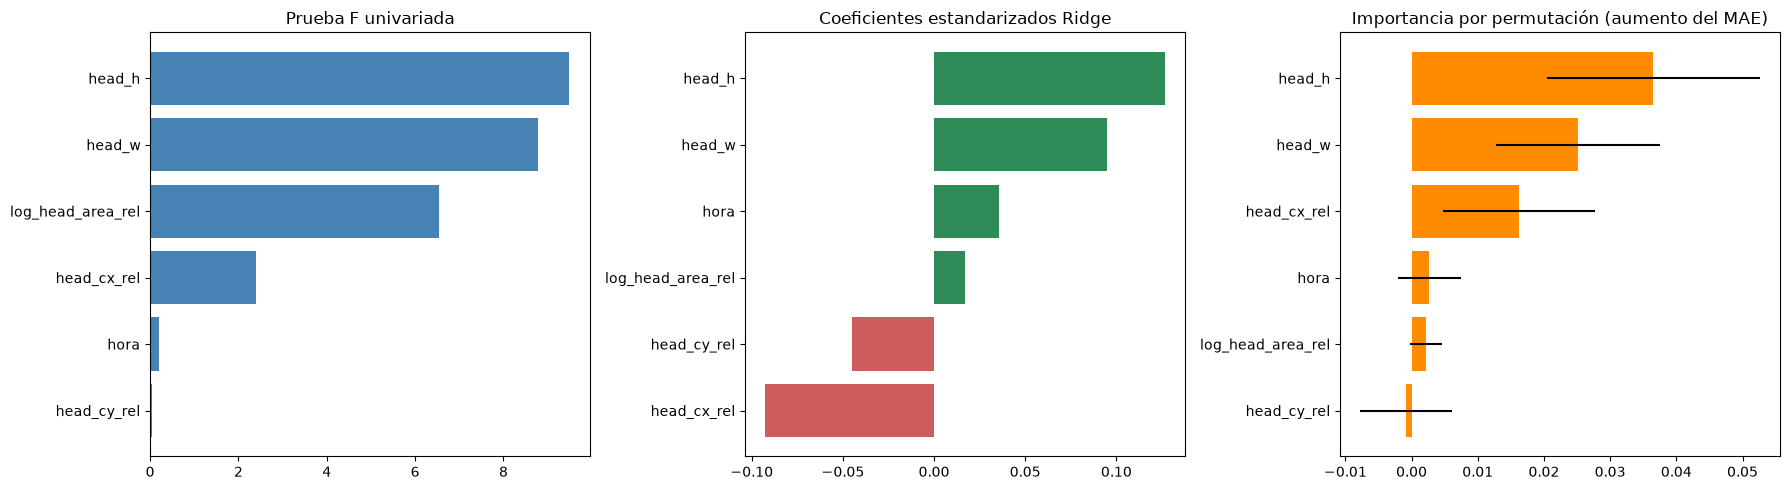

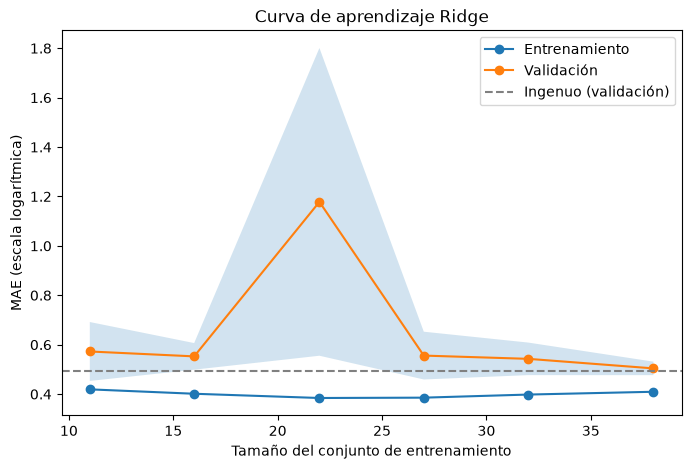

In [235]:
# Estadísticos F y valor P
estadisticos(modelos["Ridge (alpha=10)"],X_train,y_train,modelos["Ridge (alpha=10)"].named_steps["ridge"].coef_,"Ridge")
#Curva de aprendizaje
aprendizaje_curva(modelos["Ridge (alpha=10)"],X_train,y_train,"Ridge")


## Modelo 3 - Regresion gamma

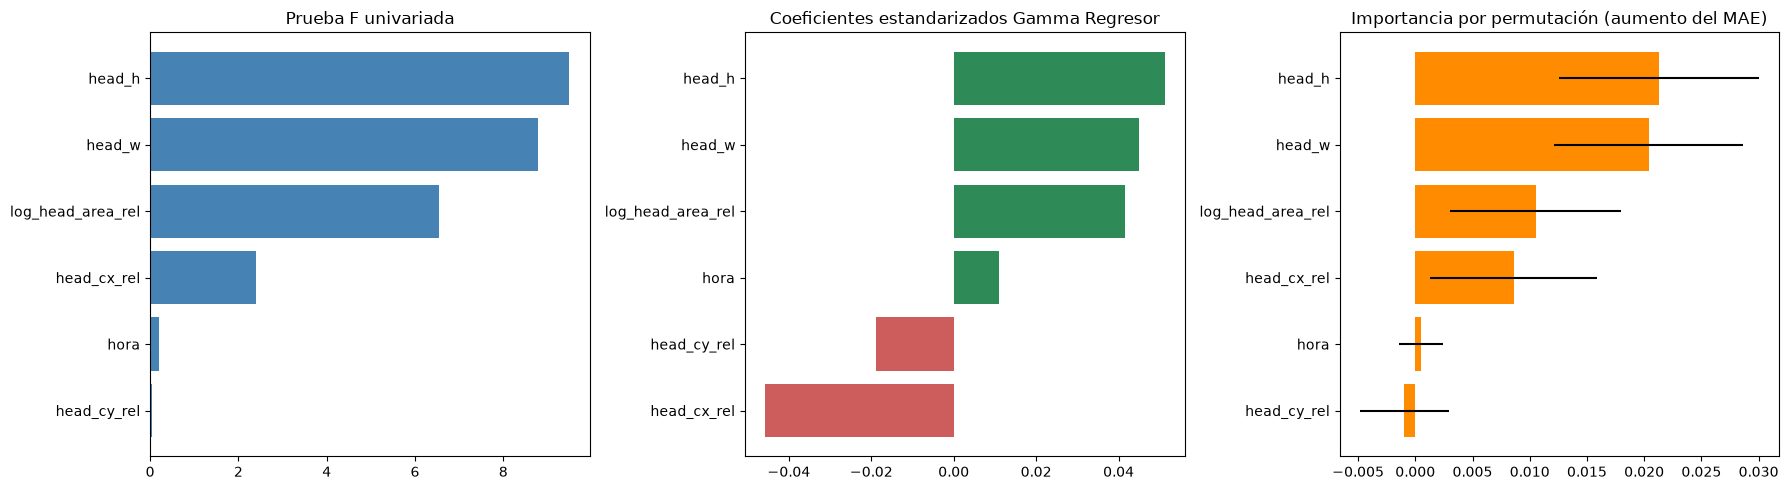

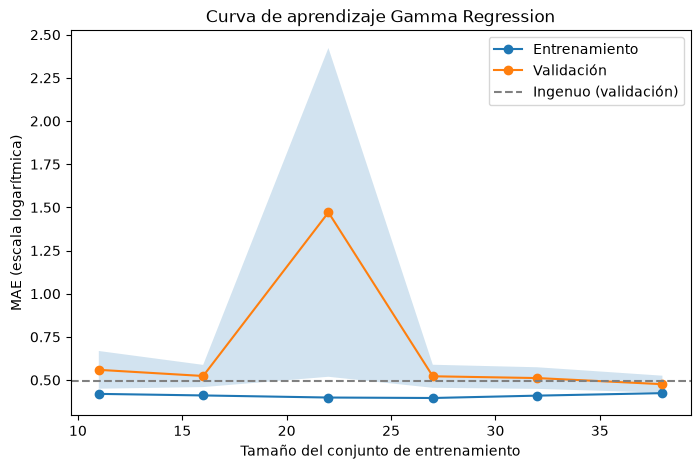

In [236]:
# Estadísticos F y valor P
estadisticos(modelos["Gamma Regression"],X_train,y_train,modelos["Gamma Regression"].named_steps["gammaregressor"].coef_,"Gamma Regresor")
aprendizaje_curva(modelos["Gamma Regression"],X_train,y_train,"Gamma Regression")

## Modelo 4 - Bayesian Ridge

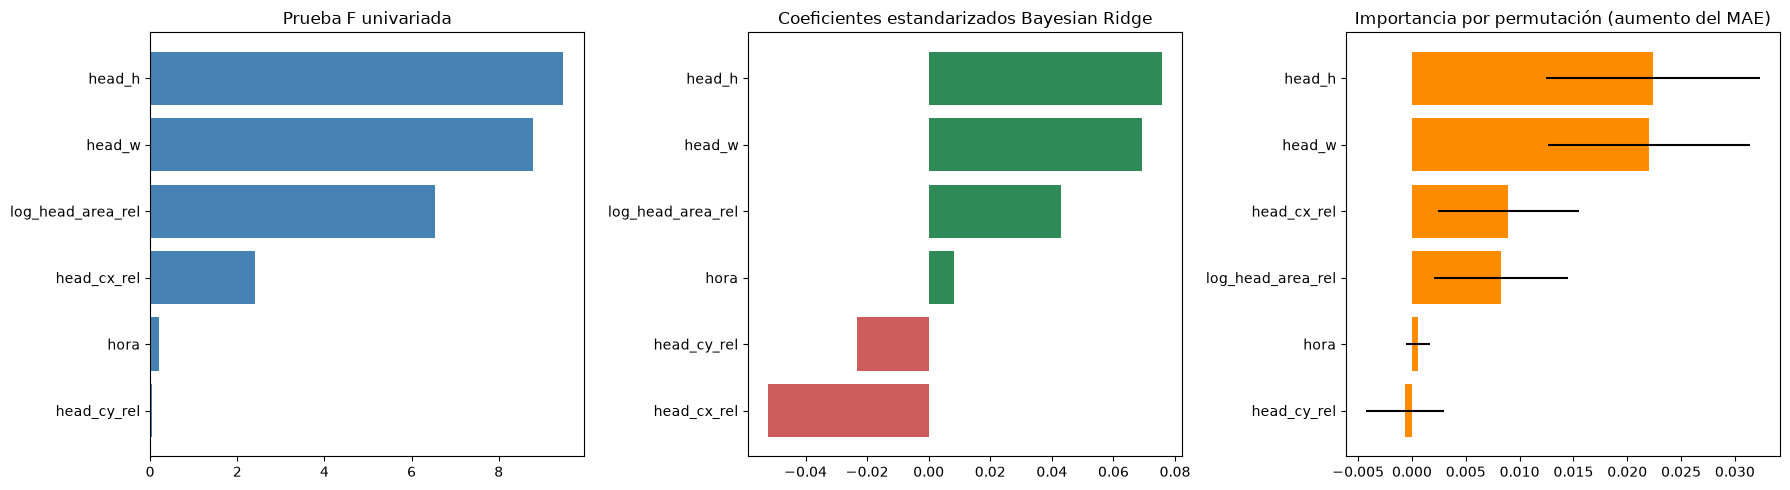

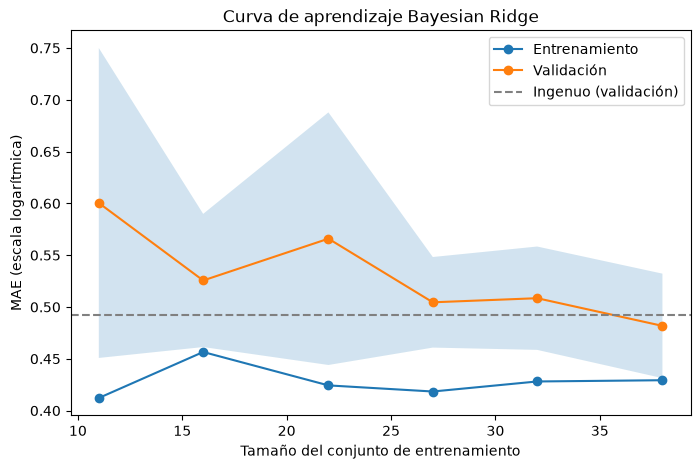

In [237]:
# Estadísticos F y valor P
estadisticos(modelos["Bayesian Ridge"],X_train,y_train,modelos["Bayesian Ridge"].named_steps["bayesianridge"].coef_,"Bayesian Ridge")
aprendizaje_curva(modelos["Bayesian Ridge"],X_train,y_train,"Bayesian Ridge")

## Modelo 5 - SGD Regressor

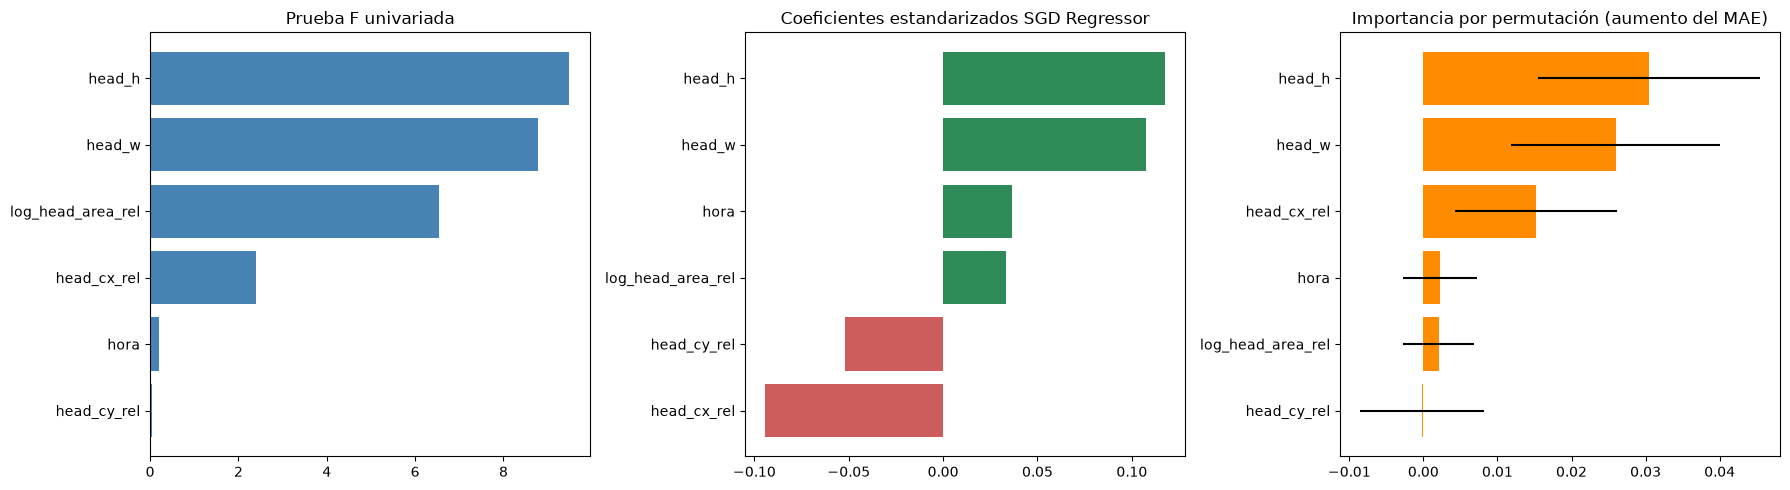

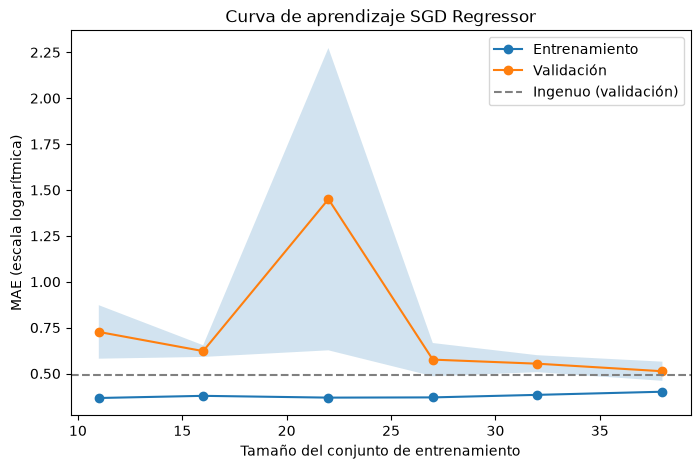

In [238]:
# Estadísticos F y valor P
estadisticos(modelos["SGDRegressor"],X_train,y_train,modelos["SGDRegressor"].named_steps["sgdregressor"].coef_,"SGD Regressor")
#Curvas de aprendizaje
aprendizaje_curva(modelos["SGDRegressor"],X_train,y_train,"SGD Regressor")

## Modelo 6 - Random forest regressor

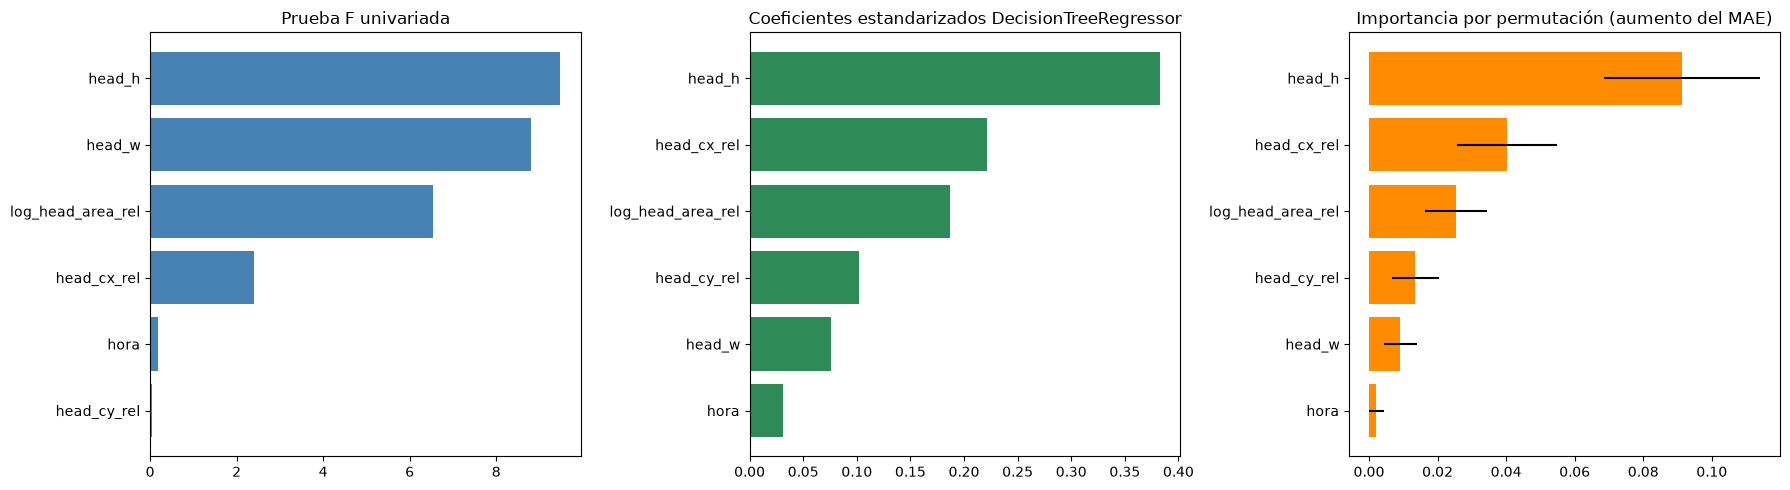

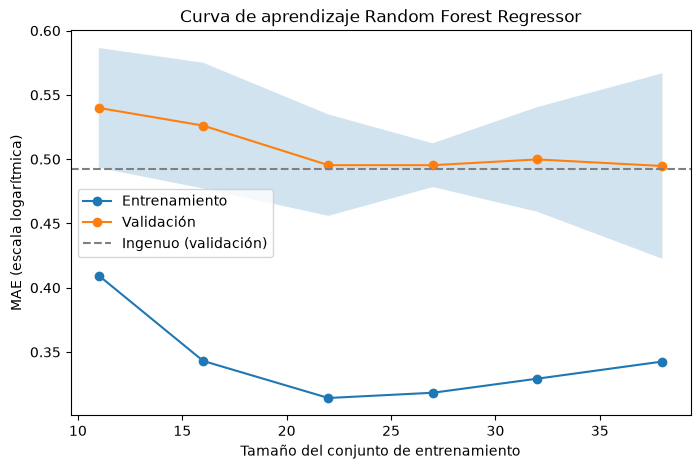

In [239]:
# Estadísticos F y valor P
estadisticos(modelos["Random Forest"],X_train,y_train,modelos["Random Forest"].feature_importances_,"DecisionTreeRegressor")
# Curva de aprendizaje
aprendizaje_curva(modelos["Random Forest"],X_train,y_train,"Random Forest Regressor")

## Modelo 7 - MLP Regressor

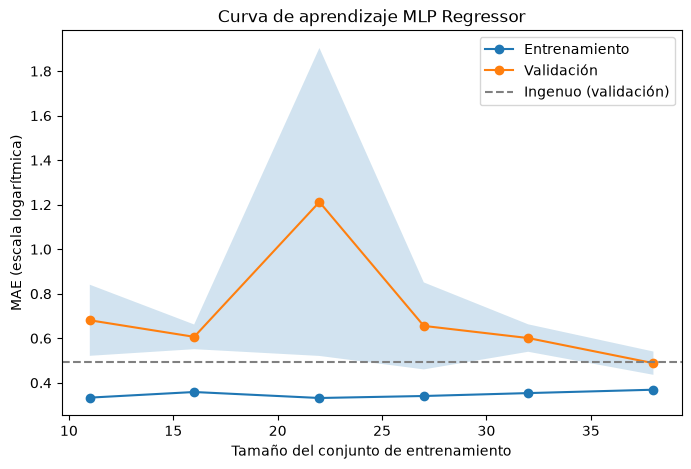

In [240]:
# Estadísticos F y valor P
#estadisticos(modelos["Red neuronal (MLP)"],X_train,y_train,modelos["Red neuronal (MLP)"],"MLP Regressor")
#Curva de aprendizaje
aprendizaje_curva(modelos["Red neuronal (MLP)"],X_train,y_train,"MLP Regressor")

# Comparativa
## Analítica de errores de todos los modelos

In [241]:
cv = GroupKFold(n_splits=5)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

filas_cv = []
for nombre, m in construir_modelos().items():
    r = cross_validate(m, X_train, y_train, groups=g_train, cv=cv, scoring=scoring, return_train_score=True)
    filas_cv.append({"Modelo": nombre,
                     "MAE train": -r["train_mae"].mean(), "MAE val": -r["test_mae"].mean(), "MAE val (std)": r["test_mae"].std(),
                     "RMSE val": -r["test_rmse"].mean(),
                     "R2 train": r["train_r2"].mean(), "R2 val": r["test_r2"].mean(), "R2 val (std)": r["test_r2"].std()})
cv_res = pd.DataFrame(filas_cv).set_index("Modelo")
cv_res.round(3)

,MAE train,MAE val,MAE val (std),RMSE val,R2 train,R2 val,R2 val (std)
Modelo,,,,,,,
Ingenuo (media),0.486,0.493,0.050,0.571,0.000,-0.078,0.102
Regresión lineal,0.397,0.548,0.065,0.653,0.275,-0.548,0.608
Ridge (alpha=10),0.411,0.505,0.032,0.596,0.256,-0.252,0.413
Gamma Regression,0.427,0.477,0.051,0.564,0.217,-0.093,0.318
Bayesian Ridge,0.428,0.483,0.055,0.575,0.215,-0.137,0.339
SGDRegressor,0.402,0.510,0.049,0.615,0.239,-0.363,0.540
Random Forest,0.342,0.503,0.093,0.606,0.472,-0.300,0.586
Red neuronal (MLP),0.370,0.492,0.063,0.592,0.384,-0.245,0.465


En lo general parecen desempeñarse de manera semejante, lo destacable es que el "Random Forest" muestra indicios de overfitting y el Bayesian parece ser bueno generalizando.
En cuanto a desempeño el Ridge uno de los de mejor desempeño, así como el Regressor Gamma.  Tal desempeño puede deberse a una ajuste de hiperparámetros por lo que las *redes MLP* y *Random Forest* tienen potencial de ajuste fino.   

# Ajuste fino
Se realiza un "Grid search" para ambos algoritmos ajustables (GPT-6 Luna):

In [242]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import pandas as pd

RANDOM_STATE = 42
n_splits = min(5, groups_train.nunique())

if n_splits < 2:
    raise ValueError("Se necesitan imágenes suficientes para validación cruzada.")

cv = GroupKFold(n_splits=n_splits)

# Random Forest: se controla el tamaño de los árboles para limitar complejidad.
rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=1  # El paralelismo se deja al buscador.
)

rf_params = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 3, 5, 8],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, 0.7, "sqrt"],
}

search_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_params,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)

search_rf.fit(X_train, y_train, groups=groups_train)


# MLP: escalado dentro del pipeline para que se ajuste en cada partición.
# LBFGS puede ser una opción razonable para conjuntos pequeños.
mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        solver="lbfgs",
        max_iter=3000,
        random_state=RANDOM_STATE,
    )
)

mlp_params = {
    "mlpregressor__hidden_layer_sizes": [
        (4,), (8,), (16,), (8, 4), (16, 8)
    ],
    "mlpregressor__alpha": [0.001, 0.01, 0.1, 1.0],
    "mlpregressor__activation": ["relu", "tanh"],
}

search_mlp = RandomizedSearchCV(
    estimator=mlp,
    param_distributions=mlp_params,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)

search_mlp.fit(X_train, y_train, groups=groups_train)


# Mostrar los mejores parámetros y MAE promedio de validación cruzada.
resultados = []

for nombre, busqueda in [
    ("Random Forest", search_rf),
    ("MLP", search_mlp),
]:
    resultados.append({
        "modelo": nombre,
        "MAE_validación_CV": -busqueda.best_score_,
        "mejores_parámetros": busqueda.best_params_,
    })

display(pd.DataFrame(resultados))


,modelo,MAE_validación_CV,mejores_parámetros
0,Random Forest,0.485404,"{'n_estimators': 100, 'min_samples_split': 10,..."
1,MLP,0.491822,"{'mlpregressor__hidden_layer_sizes': (8,), 'ml..."


In [243]:
mejores_modelos = {
    "Random Forest": search_rf.best_estimator_,
    "MLP": search_mlp.best_estimator_,
}

for nombre, modelo in mejores_modelos.items():
    pred = modelo.predict(X_test)
    mae_test = mean_absolute_error(y_test, pred)
    print(f"{nombre} — MAE en test: {mae_test:.4f}")


Random Forest — MAE en test: 0.5360
MLP — MAE en test: 0.4833


# Modelo individual

Text(0.5, 1.0, 'MLP ajustado')

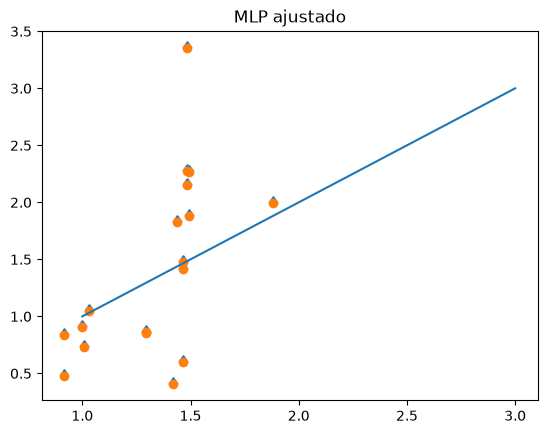

In [253]:
y_hat=search_mlp.predict(X_test)
y_hat_ori=modelos["Red neuronal (MLP)"].predict(X_test)
plt.scatter(y_hat_ori,y_test,marker=10)
plt.scatter(y_hat,y_test)
plt.plot([1,3],[1,3])
plt.title("MLP ajustado")